<a href="https://colab.research.google.com/github/prajwalms07/DAV_Lab_Programs/blob/main/4NI25CS141_prg6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

#Loading of dataset
df = pd.read_csv(r"/content/winequality-red.csv")

print("First 5 rows")
print(df.head())

print("\nShape of dataset")
print(df.shape)

print("\nColumns Names")
print(df.columns)

print("\nMissing values")
print(df.isnull().sum())

First 5 rows
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Shape of dataset
(1599, 12)

Columns Names
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
dens


Normalized Data(first 5 rows): 
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0          0.248             0.397         0.00  ...  0.606      0.138    0.154
1          0.283             0.521         0.00  ...  0.362      0.210    0.215
2          0.283             0.438         0.04  ...  0.409      0.192    0.215
3          0.584             0.110         0.56  ...  0.331      0.150    0.215
4          0.248             0.397         0.00  ...  0.606      0.138    0.154

[5 rows x 11 columns]

Standardized Data(first 5 rows): 
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0         -0.528             0.962       -1.391  ...  1.289     -0.579   -0.960
1         -0.299             1.967       -1.391  ... -0.720      0.129   -0.585
2         -0.299             1.297       -1.186  ... -0.331     -0.048   -0.585
3          1.655            -1.384        1.484  ... -0.979     -0.461   -0.585
4         -0.528             

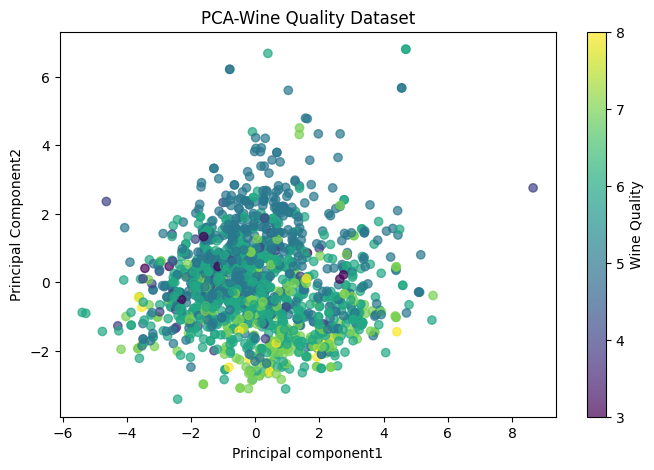

In [10]:
#2. Separate input features and target
x = df.drop("quality", axis=1)
y = df["quality"]

#3. Normalisation
normalizer = MinMaxScaler()
x_normalized = normalizer.fit_transform(x)
print("\nNormalized Data(first 5 rows): ")
print(pd.DataFrame(x_normalized,columns=x.columns).head().round(3))

#4. Standardization
standardizer = StandardScaler()
x_standardized = standardizer.fit_transform(x)
print("\nStandardized Data(first 5 rows): ")
print(pd.DataFrame(x_standardized,columns=x.columns).head().round(3))

#5.Apply PCA for dimensionality reduction
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_standardized)

print("\nPCA Data(first 5 rows): ")
print(pd.DataFrame(x_pca,columns=["PC1","PC2"]).head().round(3))
print("\nOriginal number of features:",x.shape[1])
print("Reduced number of features:",x_pca.shape[1])

print("\nVariance Retained by each component:")
print(pca.explained_variance_ratio_.round(4))
print("Total variance retained:",round(sum(pca.explained_variance_ratio_)*100,2),"%")

#6. Visualize the PCA result
plt.figure(figsize=(8, 5))
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap='viridis',alpha=0.7)
plt.xlabel('Principal component1')
plt.ylabel('Principal Component2')
plt.title('PCA-Wine Quality Dataset')
plt.colorbar(label='Wine Quality')
plt.show()
